# 🛍️ Exploratory Data Analysis & Model Comparison

This notebook explores the product and interaction data, then trains and compares the recommenders in `src/`.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.data_preprocessing import *
from src.collaborative_filtering import UserBasedCF, SVDRecommender
from src.content_based import ContentBasedRecommender
from src.hybrid_recommender import HybridRecommender, popular_products
from src.evaluation import evaluate_ranking, evaluate_rmse
sns.set_theme(style="whitegrid")

## 1. Load & clean

In [2]:
products, interactions = load_and_prepare()
print(products.shape, interactions.shape)
print("Missing values:", products.isna().sum().sum(), interactions[['user_id','product_id','score']].isna().sum().sum())
products.head()

(240, 5) (7985, 5)
Missing values: 0 0


,product_id,product_name,category,description,price
0,1,Lite Headphones 215,Electronics,Lite headphones for electronics lovers. Featur...,115.34
1,2,Essential Smartwatch 844,Electronics,Essential smartwatch for electronics lovers. F...,159.76
2,3,Lite Headphones 238,Electronics,Lite headphones for electronics lovers. Featur...,172.35
3,4,Lite Webcam 303,Electronics,Lite webcam for electronics lovers. Features: ...,169.10
4,5,Premium Webcam 713,Electronics,Premium webcam for electronics lovers. Feature...,39.24


In [3]:
interactions.head()

,user_id,product_id,rating,interaction_type,score
0,1,29,NaN,click,1.0
1,1,33,NaN,click,1.0
2,1,34,4.0,purchase,4.0
3,1,36,NaN,add_to_cart,3.0
4,1,44,5.0,purchase,5.0


## 2. Exploratory analysis

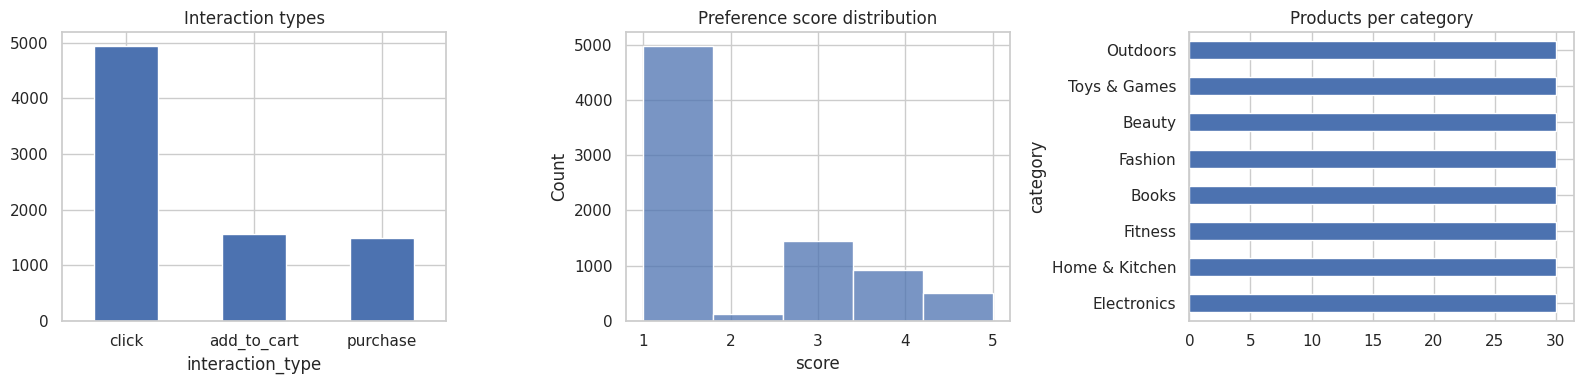

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
interactions["interaction_type"].value_counts().plot.bar(ax=ax[0], title="Interaction types", rot=0)
sns.histplot(interactions["score"], bins=5, ax=ax[1]).set_title("Preference score distribution")
products["category"].value_counts().plot.barh(ax=ax[2], title="Products per category")
plt.tight_layout(); plt.show()

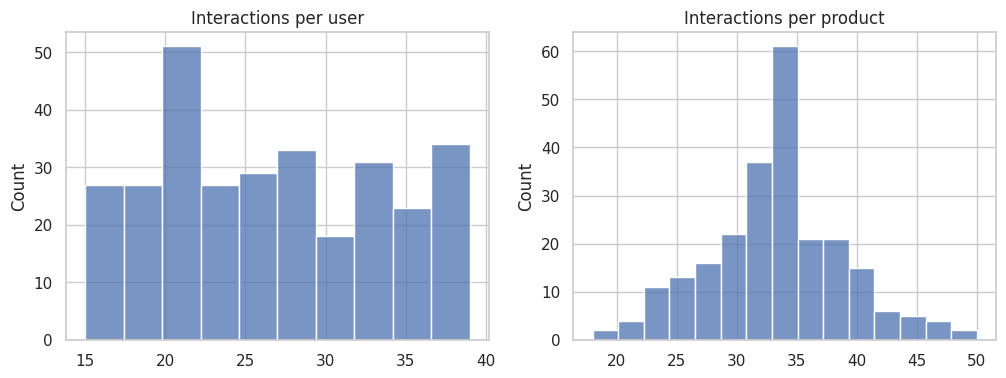

Matrix: (300, 240), sparsity = 88.9%


In [5]:
per_user = interactions.groupby("user_id").size()
per_item = interactions.groupby("product_id").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per_user, ax=ax[0]).set_title("Interactions per user")
sns.histplot(per_item, ax=ax[1]).set_title("Interactions per product")
plt.show()
matrix_full = build_user_item_matrix(interactions)
print(f"Matrix: {matrix_full.shape}, sparsity = {1 - (matrix_full.values > 0).mean():.1%}")

In [6]:
top = (interactions.merge(products, on="product_id").groupby(["product_name", "category"])
       .agg(n=("score", "size"), avg=("score", "mean")).sort_values("n", ascending=False).head(10))
top

,,n,avg
product_name,category,,
Pro Blender 804,Home & Kitchen,50,1.960000
Classic Webcam 600,Electronics,49,2.244898
Premium Backpack 343,Fashion,47,2.085106
Prime Shampoo 577,Beauty,47,2.021277
Prime Blender 399,Home & Kitchen,47,1.829787
Ultra Charger 203,Electronics,46,1.869565
Essential Toaster 864,Home & Kitchen,45,2.355556
Eco Jump Rope 211,Fitness,45,1.600000
Prime Backpack 941,Fashion,45,1.777778


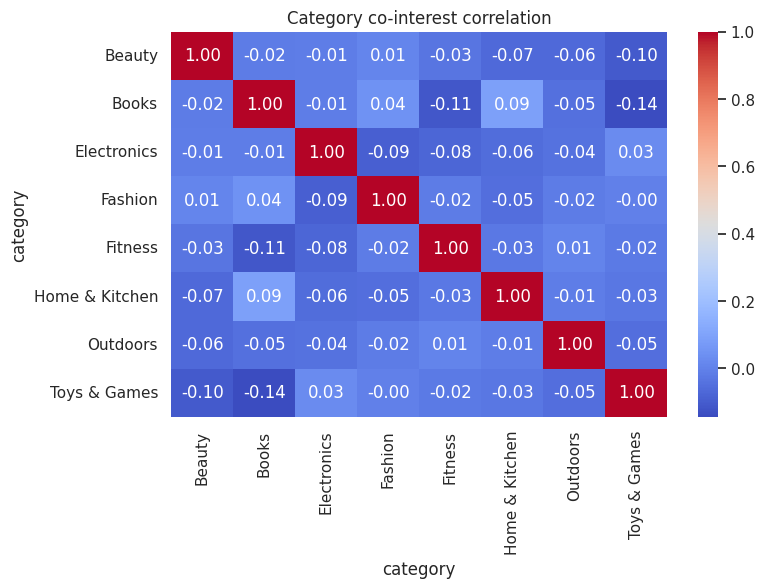

In [7]:
cat_user = interactions.merge(products[["product_id","category"]], on="product_id").pivot_table(
    index="user_id", columns="category", values="score", aggfunc="count", fill_value=0)
plt.figure(figsize=(8, 5)); sns.heatmap(cat_user.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Category co-interest correlation"); plt.show()

## 3. Train / test split

In [8]:
train, test = train_test_split_interactions(interactions)
pids = products["product_id"].tolist()
users = sorted(interactions["user_id"].unique())
M = build_user_item_matrix(train, product_ids=pids, user_ids=users)
print(len(train), len(test))

6386 1599


## 4. Fit models

In [9]:
ucf = UserBasedCF(n_neighbors=30).fit(M)
svd = SVDRecommender(n_factors=20).fit(M)
cb = ContentBasedRecommender().fit(products)
hybrid = HybridRecommender(ucf, cb, train, alpha=0.7)
cb.similar_products(1, 5).to_frame("similarity").join(products.set_index("product_id")[["product_name", "category"]])

,similarity,product_name,category
3,0.522529,Lite Headphones 238,Electronics
30,0.261729,Elite Headphones 800,Electronics
12,0.249045,Premium Headphones 488,Electronics
20,0.247241,Prime Headphones 276,Electronics
26,0.246868,Max Headphones 159,Electronics


## 5. Compare ranking quality

In [10]:
K = 10
models = {
    "Popularity": lambda u, k: popular_products(train, k),
    "User-based CF": ucf.recommend,
    "SVD": svd.recommend,
    "Content-based": lambda u, k: cb.recommend(M.loc[u], k),
    "Hybrid (User CF + content)": hybrid.recommend,
}
results = pd.DataFrame({name: evaluate_ranking(fn, test, K) for name, fn in models.items()}).T
results.style.format("{:.3f}").highlight_max(axis=0)

,Precision@10,Recall@10,NDCG@10
Popularity,0.006,0.029,0.018
User-based CF,0.046,0.215,0.128
SVD,0.025,0.116,0.071
Content-based,0.047,0.229,0.124
Hybrid (User CF + content),0.047,0.229,0.134


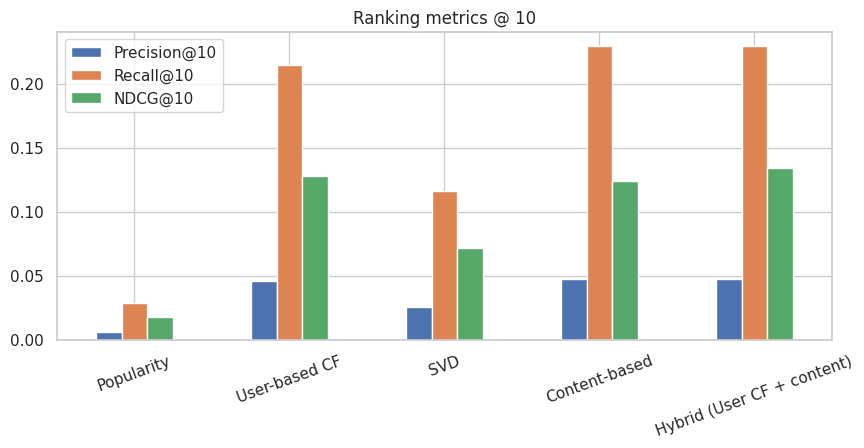

In [11]:
results.plot.bar(figsize=(10, 4), rot=20, title=f"Ranking metrics @ {K}"); plt.show()

## 6. Rating prediction (RMSE)

Explicit ratings are sparse, so this model is fit on explicit ratings only and compared with a global-mean baseline.

In [12]:
explicit = train.dropna(subset=["rating"]).assign(score=lambda d: d["rating"])
M_exp = build_user_item_matrix(explicit, product_ids=pids, user_ids=users)
svd_r = SVDRecommender(n_factors=10).fit(M_exp)
gm = explicit["rating"].mean()
print("SVD RMSE:            ", round(evaluate_rmse(svd_r.predict_rating, test), 3))
print("Global-mean baseline:", round(evaluate_rmse(lambda u, p: gm, test), 3))

SVD RMSE:             1.127
Global-mean baseline: 1.046


## 7. Cold start & tuning the hybrid weight

Unknown user -> [104, 69, 57, 221, 17] (popular products)


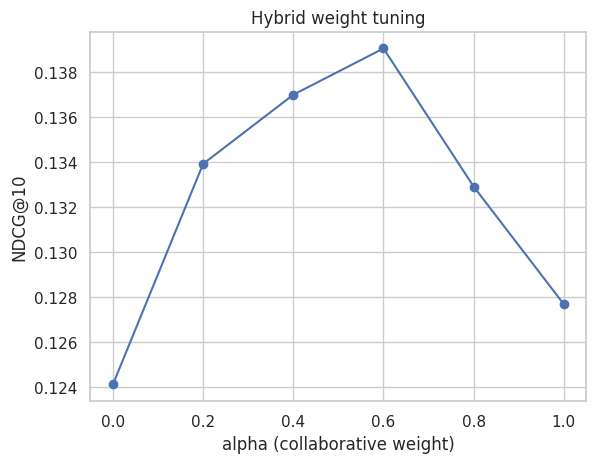

In [13]:
print("Unknown user ->", hybrid.recommend(user_id=-1, k=5).index.tolist(), "(popular products)")
alphas = np.linspace(0, 1, 6)
curve = [evaluate_ranking(HybridRecommender(ucf, cb, train, a).recommend, test, K)[f"NDCG@{K}"] for a in alphas]
plt.plot(alphas, curve, marker="o"); plt.xlabel("alpha (collaborative weight)"); plt.ylabel(f"NDCG@{K}")
plt.title("Hybrid weight tuning"); plt.show()

**Takeaways** – Personalised models strongly outperform popularity; the hybrid combines the strengths of collaborative and content signals. Replace the synthetic data in `data/` with a real dataset to see how the approaches behave in practice.